# 1. Data and labels

What the wildfire model learns from: where the labels come from and why, what the
training table looks like, and whether the weather features carry a signal.

This notebook only reads what `python -m ml.wildfire.build_dataset` already built and
cached (run that first, from `backend/`). It makes one small network request, for the
InFORM comparison below, and runs in under a minute.

In [1]:
import viz

viz.setup()

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml.wildfire import features as F
from ml.wildfire import sources
from ml.wildfire.config import (
    ARTIFACTS_DIR, CALIBRATION_YEARS, DATASET_PATH, FIRST_YEAR, LAST_YEAR,
    REFERENCE_PATH, REFIT_YEARS, TEST_YEARS, USER_AGENT,
)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

import httpx

## Why MTBS for the labels

The model is trained on 2010-2020 and tested on 2021 onward, so a fire label has to
mean the same thing in both periods.

- **InFORM** (NIFC) holds every reported wildfire, small ones included. From 2020,
  state and local agencies started reporting into it, so its yearly counts jump.
- **MTBS** maps large fires (about 1,000+ acres in the West, 500+ in the East) from
  satellite imagery with the same method every year.

The shaded years are the test period.

In [2]:
fires = sources.load_mtbs_fires()
years = range(FIRST_YEAR, LAST_YEAR + 1)
mtbs_per_year = fires["ig_date"].dt.year.value_counts().reindex(years, fill_value=0)

INFORM_URL = (
    "https://services3.arcgis.com/T4QMspbfLg3qTGWY/arcgis/rest/services/"
    "InFORM_FireOccurrence_Public/FeatureServer/0/query"
)
try:
    response = httpx.get(
        INFORM_URL,
        headers={"User-Agent": USER_AGENT},
        timeout=60,
        params={
            "where": f"IncidentTypeCategory='WF' AND CalendarYear>={FIRST_YEAR} AND CalendarYear<={LAST_YEAR}",
            "outStatistics": json.dumps(
                [{"statisticType": "count", "onStatisticField": "OBJECTID", "outStatisticFieldName": "n"}]
            ),
            "groupByFieldsForStatistics": "CalendarYear",
            "f": "json",
        },
    )
    counts = {f["attributes"]["CalendarYear"]: f["attributes"]["n"] for f in response.json()["features"]}
    inform_per_year = pd.Series(counts).reindex(years)
except Exception as error:  # The comparison is optional; the rest of the notebook doesn't need it
    inform_per_year = None
    print("Couldn't reach InFORM, skipping it:", error)

pd.DataFrame({"InFORM: all reported wildfires": inform_per_year, "MTBS: large wildfires": mtbs_per_year})

,InFORM: all reported wildfires,MTBS: large wildfires
2010,16395,294
2011,17212,824
2012,20012,569
2013,16917,303
2014,16398,267
2015,20320,536
2016,16933,518
2017,17769,644
2018,25400,525
2019,26137,379


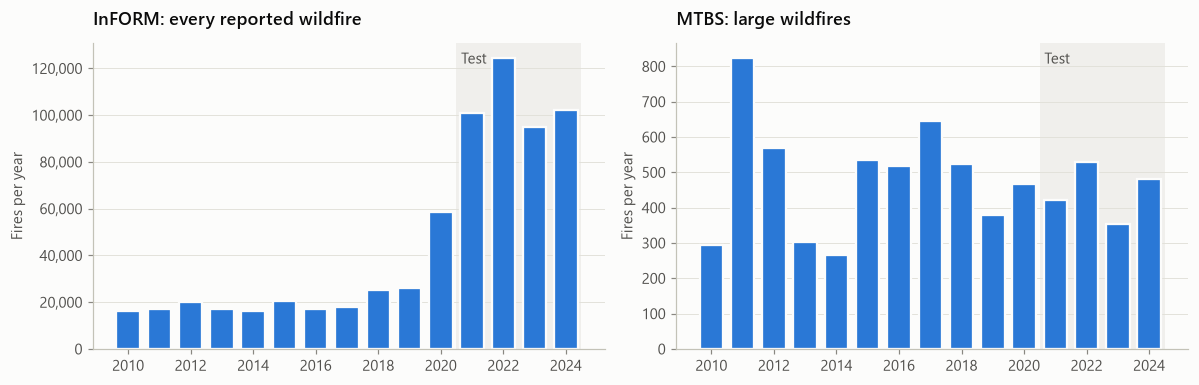

In [3]:
panels = [("InFORM: every reported wildfire", inform_per_year), ("MTBS: large wildfires", mtbs_per_year)]
panels = [(title, series) for title, series in panels if series is not None]
fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 3.6), squeeze=False)
for ax, (title, series) in zip(axes[0], panels):
    ax.axvspan(min(TEST_YEARS) - 0.5, max(TEST_YEARS) + 0.5, color="#f0efec", zorder=0)
    viz.bars(ax, series.index, series.to_numpy())
    ax.set_title(title)
    ax.set_ylabel("Fires per year")
    ax.set_xticks(list(years)[::2])
    ax.text(min(TEST_YEARS) - 0.35, ax.get_ylim()[1] * 0.97, "Test", color=viz.INK_SECONDARY, va="top")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    viz.finish(ax)
viz.show()

InFORM's count rises about fivefold between 2019 and 2022, mostly because more agencies
report to it. Labels from it would make the test years look far more fire-prone than
the training years for reasons unrelated to fire risk. MTBS stays in the same range
throughout (about 270 to 820 a year, varying with each year's weather), so it's the
label source. The trade-off is that the model predicts **large** fires only.

## The training table

One row per county and week (Monday to Sunday). `fire` is 1 when an MTBS wildfire's
ignition point is in the county that week.

In [4]:
data = pd.read_parquet(DATASET_PATH)
print(f"{len(data):,} county-weeks, {data['fips'].nunique():,} counties, "
      f"{data['week_start'].nunique():,} weeks, {len(F.FEATURES)} features")

splits = {
    "Training (2010-2018)": REFIT_YEARS,
    "Calibration (2019-2020)": CALIBRATION_YEARS,
    "Test (2021-2024)": TEST_YEARS,
}
rows = []
for name, split_years in splits.items():
    part = data[data["year"].isin(list(split_years))]
    rows.append({"Split": name, "County-weeks": len(part), "Fires": int(part["fire"].sum()),
                 "Fire rate": part["fire"].mean()})
pd.DataFrame(rows).set_index("Split").style.format({"County-weeks": "{:,}", "Fires": "{:,}", "Fire rate": "{:.3%}"})

2,518,822 county-weeks, 3,221 counties, 782 weeks, 36 features


,County-weeks,Fires,Fire rate
Split,,,
Training (2010-2018),"1,510,649","3,637",0.241%
Calibration (2019-2020),"338,205",714,0.211%
Test (2021-2024),"669,968","1,442",0.215%


In [5]:
data.head()

,fips,week_start,year,fire,week_tmax_mean,week_tmax_max,week_vpd_mean,week_vpd_max,week_rhmin_mean,week_rhmin_min,...,hist_50km_rate,hist_100km_rate,hist_100km_month_rate,lat,lon,elevation_m,log_area_km2,log_pop_density,woy_sin,woy_cos
0,01001,2010-01-04,2010,0,1.731429,3.77,0.352976,0.450420,49.388878,42.587067,...,0.038462,0.230769,0.038462,32.536201,-86.641197,131.0,7.356796,3.656273,0.000000,1.000000
1,01001,2010-01-11,2010,0,9.057143,13.00,0.473882,0.751224,58.291241,45.636112,...,0.038462,0.230769,0.038462,32.536201,-86.641197,131.0,7.356796,3.656273,0.120537,0.992709
2,01001,2010-01-18,2010,0,17.481428,22.17,0.737014,0.885430,63.400547,52.020832,...,0.038462,0.230769,0.038462,32.536201,-86.641197,131.0,7.356796,3.656273,0.239316,0.970942
3,01001,2010-01-25,2010,0,12.890000,16.60,0.769713,1.166671,49.087067,38.243675,...,0.038462,0.230769,0.038462,32.536201,-86.641197,131.0,7.356796,3.656273,0.354605,0.935016
4,01001,2010-02-01,2010,0,10.821428,13.83,0.457135,0.628321,64.981659,51.288925,...,0.038462,0.230769,0.000000,32.536201,-86.641197,131.0,7.356796,3.656273,0.464723,0.885456


Fires are rare: about 1 county-week in 450. That's why training weights fire rows by
`scale_pos_weight` and why the probabilities are calibrated afterwards (notebook 2).

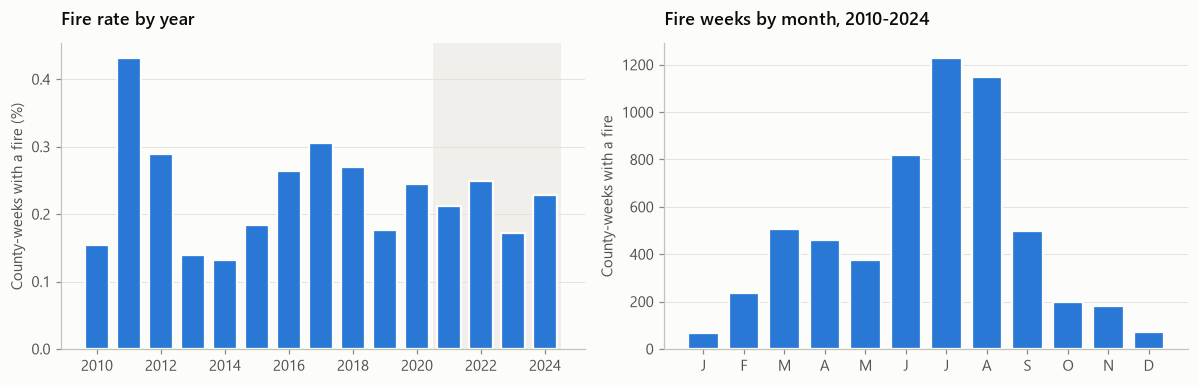

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

rate_by_year = data.groupby("year")["fire"].mean() * 100
ax = axes[0]
ax.axvspan(min(TEST_YEARS) - 0.5, max(TEST_YEARS) + 0.5, color="#f0efec", zorder=0)
viz.bars(ax, rate_by_year.index, rate_by_year.to_numpy())
ax.set_title("Fire rate by year")
ax.set_ylabel("County-weeks with a fire (%)")
ax.set_xticks(list(years)[::2])
viz.finish(ax)

months = F.week_month(data.loc[data["fire"] == 1, "week_start"])
by_month = months.value_counts().reindex(range(1, 13), fill_value=0)
ax = axes[1]
viz.bars(ax, by_month.index, by_month.to_numpy())
ax.set_title("Fire weeks by month, 2010-2024")
ax.set_ylabel("County-weeks with a fire")
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
viz.finish(ax)
viz.show()

The fire rate varies from year to year with the weather, but the test years sit in
the same range as the training years, so they aren't systematically easier or harder.
Large fires peak from June to August, with a smaller peak in March and April.

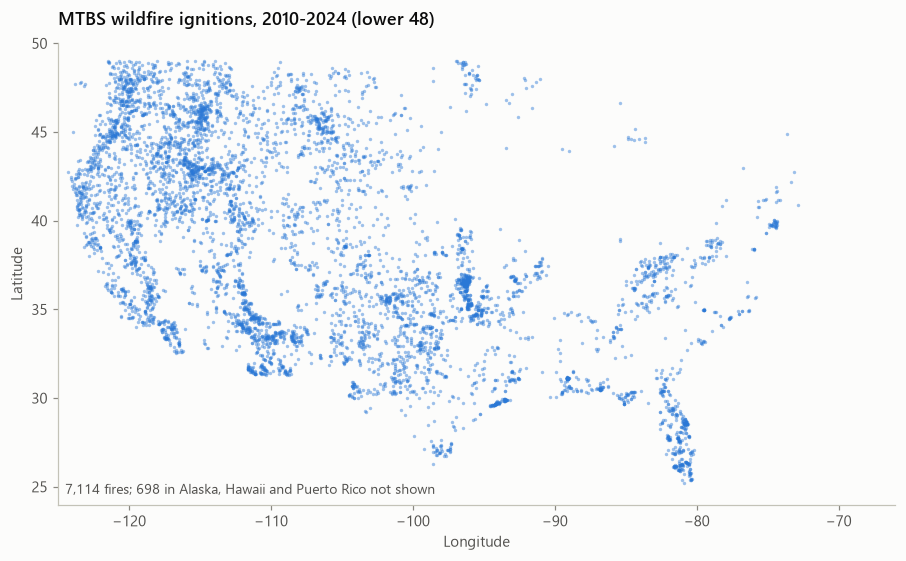

In [7]:
labelled = fires[fires["ig_date"].dt.year.between(FIRST_YEAR, LAST_YEAR)]
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.scatter(labelled["longitude"], labelled["latitude"], s=5, color=viz.BLUE, alpha=0.45, linewidths=0)
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_aspect(1.25)
ax.set_title(f"MTBS wildfire ignitions, {FIRST_YEAR}-{LAST_YEAR} (lower 48)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(False)
outside = (~labelled["longitude"].between(-125, -66) | ~labelled["latitude"].between(24, 50)).sum()
ax.text(-124.5, 24.6, f"{len(labelled):,} fires; {outside:,} in Alaska, Hawaii and Puerto Rico not shown",
        color=viz.INK_SECONDARY, fontsize=9)
viz.show()

## Do the weather features carry a signal?

The fire rate in each tenth (decile) of a feature, across all years. The dashed line
is the average fire rate. Flat lines would mean the feature tells us nothing.

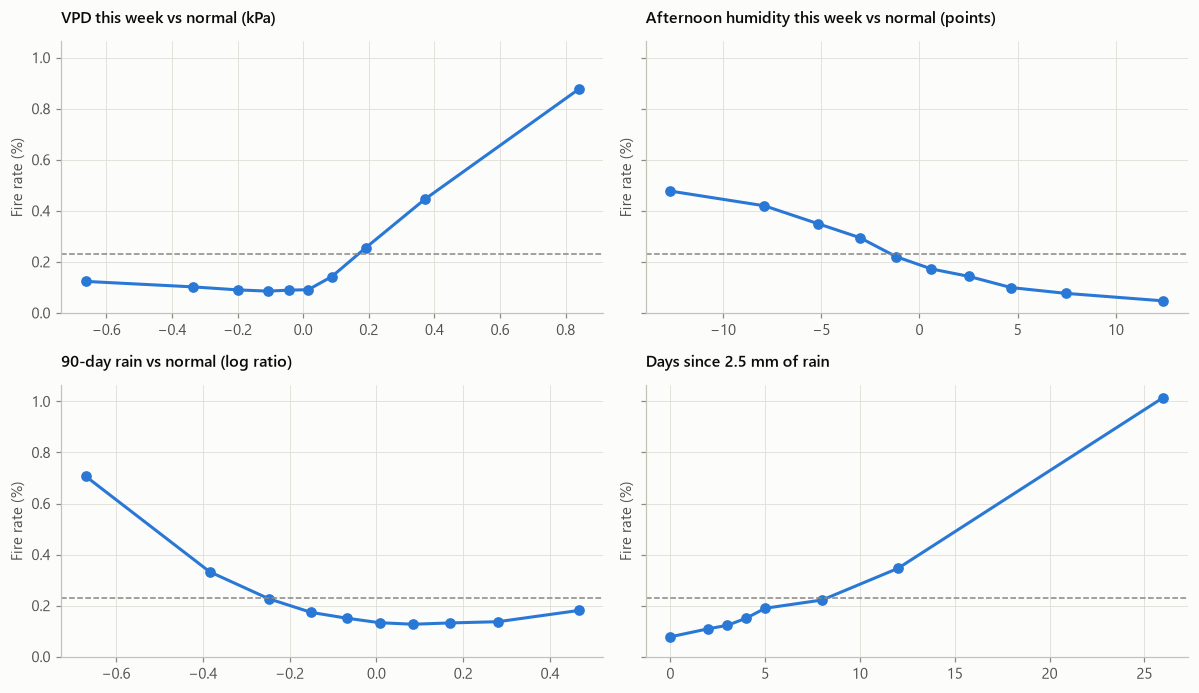

In [8]:
checks = {
    "week_vpd_mean_anom": "VPD this week vs normal (kPa)",
    "week_rhmin_mean_anom": "Afternoon humidity this week vs normal (points)",
    "prior90_precip_anom": "90-day rain vs normal (log ratio)",
    "days_since_rain": "Days since 2.5 mm of rain",
}
base_rate = data["fire"].mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharey=True)
for ax, (column, label) in zip(axes.flat, checks.items()):
    bins = pd.qcut(data[column], 10, duplicates="drop")
    grouped = data.groupby(bins, observed=True).agg(mid=(column, "median"), rate=("fire", "mean"))
    ax.plot(grouped["mid"], grouped["rate"] * 100, color=viz.BLUE, marker="o", markersize=6)
    ax.axhline(base_rate, color=viz.INK_MUTED, linestyle="--", linewidth=1)
    ax.set_title(label, fontsize=10.5)
    ax.set_ylabel("Fire rate (%)")
    viz.finish(ax, "both")
viz.show()

All four have a strong relationship with fire starts. Weeks with higher VPD and lower
humidity than normal, after a drier-than-normal 90 days or a long dry spell, have
several times the average fire rate. (Rain is not quite one-directional: the wettest
tenth is a little above the middle.) The same comparison as medians:

In [9]:
columns = ["week_tmax_mean", "week_vpd_mean", "week_rhmin_mean", "week_wind_max",
           "prior30_precip", "days_since_rain", "prior7_gwetroot", "hist_100km_month_rate"]
medians = data.groupby("fire")[columns].median().T
medians.columns = ["No fire", "Fire"]
medians.round(2)

,No fire,Fire
week_tmax_mean,20.820000,28.690001
week_vpd_mean,1.210000,2.880000
week_rhmin_mean,51.700001,25.830000
week_wind_max,7.280000,7.450000
prior30_precip,72.470001,17.520000
days_since_rain,3.000000,12.000000
prior7_gwetroot,0.580000,0.410000
hist_100km_month_rate,0.000000,0.450000
